# 04 · What did the congestion fee do? A natural experiment in the real data

**Question.** On 5 January 2025 New York started charging a congestion fee on vehicles entering
Manhattan south of 60th Street; app trips into, out of or within the zone pay a per-trip fee
(recorded in the TLC data as `cbd_congestion_fee`). What did it do, **inside the zone compared
with outside**, to trips, rider wait times, traffic speed and driver pay?

This matters for a pricing team for two reasons: it is a real, unplanned price change for riders
with a clean start date (the closest thing to an experiment in observational data), and it changes
the driver side too: pay is per mile and per minute, so faster traffic changes what a trip pays.

**Design: difference-in-differences, with a year-ago check for seasonality.**
* **Treated zones**: taxi zones where pickups are inside the charging zone. Identified from the
  data: after the start date, nearly every pickup there carries the fee.
* **Control zones**: zones where almost no pickups carry the fee (< 10%) — far enough away that
  their trips rarely enter the zone. Zones in between (partly exposed, e.g. just north of 60th St
  or near the bridges) are left out of the main comparison and used for a dose–response check.
* **Seasonality is the main threat.** January is different from December everywhere, and Midtown's
  tourist season differs from the outer boroughs'. The data starts in January 2024, so the same
  calendar weeks one year earlier (no fee) show what the treated–control gap normally does. The
  main estimate is **year over year**: the gap in Jan–Jun 2025 minus the gap in the same weeks of
  2024.
* Standard errors are **clustered by zone** (weeks within a zone are correlated).
* **Placebo tests**: pretend the fee started on dates in 2024 when nothing happened; the estimate
  should be zero.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

from ridepay import config, data, plots
from ridepay.records import show_verdict, write_metrics

SOURCE = data.source()
con = data.connect()
FEE_START = pd.Timestamp(config.CBD_FEE_START)

## Which zones are treated?

fee share before the start date: max 0.0000 (should be ~0)


,zones,trips_m,mean_fee_share
group,,,
control,166,160.286,0.038
excluded (airport),3,13.567,0.312
partly exposed,53,92.808,0.250
treated,39,93.372,0.987


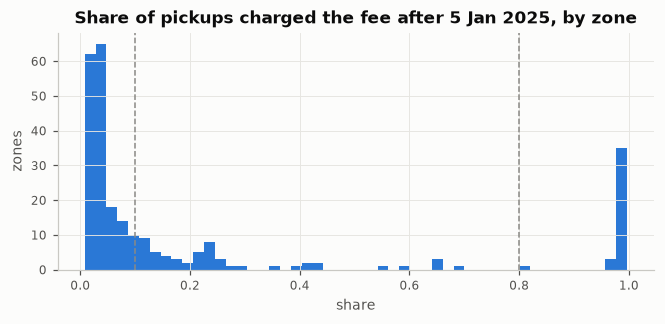

In [2]:
exposure = con.sql(f"""
    SELECT zone, zones.zone_name, zones.borough,
           SUM(CASE WHEN hour >= TIMESTAMP '{FEE_START}' THEN trips_cbd_fee END)
             / SUM(CASE WHEN hour >= TIMESTAMP '{FEE_START}' THEN trips END)      AS fee_share_after,
           SUM(CASE WHEN hour <  TIMESTAMP '{FEE_START}' THEN trips_cbd_fee END)
             / SUM(CASE WHEN hour <  TIMESTAMP '{FEE_START}' THEN trips END)      AS fee_share_before,
           SUM(trips) AS trips
    FROM zone_hour JOIN zones USING (zone) GROUP BY ALL ORDER BY ALL
""").df().set_index("zone")
exposure["group"] = np.select(
    [exposure["fee_share_after"] >= 0.8, exposure["fee_share_after"] < 0.10],
    ["treated", "control"], "partly exposed")
exposure.loc[exposure.index.isin(config.AIRPORT_ZONES), "group"] = "excluded (airport)"
fig, ax = plots.subplots(figsize=(7, 2.8))
ax.hist(exposure["fee_share_after"].dropna(), bins=50, color=plots.SERIES[0])
for x in (0.1, 0.8):
    ax.axvline(x, color=plots.GREY, ls="--", lw=1)
ax.set(title="Share of pickups charged the fee after 5 Jan 2025, by zone", xlabel="share", ylabel="zones")
data.savefig(fig, "04_fee_exposure")
print(f"fee share before the start date: max {exposure['fee_share_before'].max():.4f} (should be ~0)")
exposure.groupby("group").agg(zones=("zone_name", "size"), trips_m=("trips", lambda s: s.sum() / 1e6),
                              mean_fee_share=("fee_share_after", "mean")).round(3)

In [3]:
treated = exposure[exposure["group"] == "treated"]
print("Treated zones by borough:", treated["borough"].value_counts().to_dict())
print("Examples:", ", ".join(treated.sort_values("trips", ascending=False)["zone_name"].head(8)))

Treated zones by borough: {'Manhattan': 39}
Examples: East Village, Times Sq/Theatre District, Midtown Center, TriBeCa/Civic Center, East Chelsea, West Chelsea/Hudson Yards, Union Sq, Midtown South


## Weekly panel

Weeks run Sunday–Saturday, so the fee starts exactly at the beginning of a week. Outcomes are built
from sums (pay per trip = total pay ÷ trips, never a mean of means):

| outcome | definition |
|---|---|
| `log_trips` | log of pickups in the zone that week |
| `wait_min` | mean rider wait (minutes) |
| `mph` | average trip speed: miles ÷ hours of driving with a rider |
| `pay_per_trip` | driver pay per trip (\$) |
| `pay_per_min` | driver pay per minute with a rider (\$) |
| `miles` | trip miles per trip |

In [4]:
weekly = con.sql("""
    SELECT zone,
           CAST(hour AS DATE) - CAST((isodow(hour) % 7) AS INTEGER) AS week,     -- Sunday-start weeks
           SUM(trips) AS trips, SUM(wait_sum_sec) AS wait_sum_sec, SUM(wait_n) AS wait_n,
           SUM(miles) AS miles, SUM(trip_sec) AS trip_sec, SUM(driver_pay) AS driver_pay
    FROM zone_hour GROUP BY ALL ORDER BY ALL
""").df()
weekly["week"] = pd.to_datetime(weekly["week"])
days_in_week = con.sql("""SELECT CAST(hour AS DATE) - CAST((isodow(hour) % 7) AS INTEGER) AS week,
                                 COUNT(DISTINCT CAST(hour AS DATE)) AS days FROM zone_hour GROUP BY 1 ORDER BY 1""").df()
full_weeks = pd.to_datetime(days_in_week.loc[days_in_week["days"] == 7, "week"])
weekly = weekly[weekly["week"].isin(full_weeks)].merge(exposure[["group"]], left_on="zone", right_index=True)
weekly = weekly[weekly["trips"] >= 20]            # a zone-week needs enough trips for its averages to mean anything
weekly = weekly.assign(
    log_trips=np.log(weekly["trips"]), wait_min=weekly["wait_sum_sec"] / weekly["wait_n"] / 60,
    mph=weekly["miles"] / (weekly["trip_sec"] / 3600), pay_per_trip=weekly["driver_pay"] / weekly["trips"],
    pay_per_min=weekly["driver_pay"] / (weekly["trip_sec"] / 60), miles=weekly["miles"] / weekly["trips"],
    post=(weekly["week"] >= FEE_START).astype(int), year=weekly["week"].dt.year,
    woy=((weekly["week"] - weekly["week"].dt.year.map(lambda y: pd.Timestamp(y, 1, 1))).dt.days // 7),
)
weekly["treated"] = (weekly["group"] == "treated").astype(int)
pre_trips = weekly[weekly["post"] == 0].groupby("zone")["trips"].mean()
weekly["w"] = weekly["zone"].map(pre_trips)     # weight per-trip outcomes by the zone's usual volume
OUTCOMES = ["log_trips", "wait_min", "mph", "pay_per_trip", "pay_per_min", "miles"]
main = weekly[weekly["group"].isin(["treated", "control"])].copy()
print(f"{main['zone'].nunique()} zones ({main.groupby('group')['zone'].nunique().to_dict()}), "
      f"{main['week'].nunique()} full weeks: {main['week'].min():%d %b %Y} to {main['week'].max():%d %b %Y}")

204 zones ({'control': 166, 'treated': 38}), 77 full weeks: 07 Jan 2024 to 22 Jun 2025


## The raw picture: treated minus control, week by week

Before any regression: the gap between treated and control zones each week (pre-period volume
weighted means), with the same calendar weeks of 2024 laid over 2025. If the fee did something,
the 2025 line separates from the 2024 line at week 0 and not before.

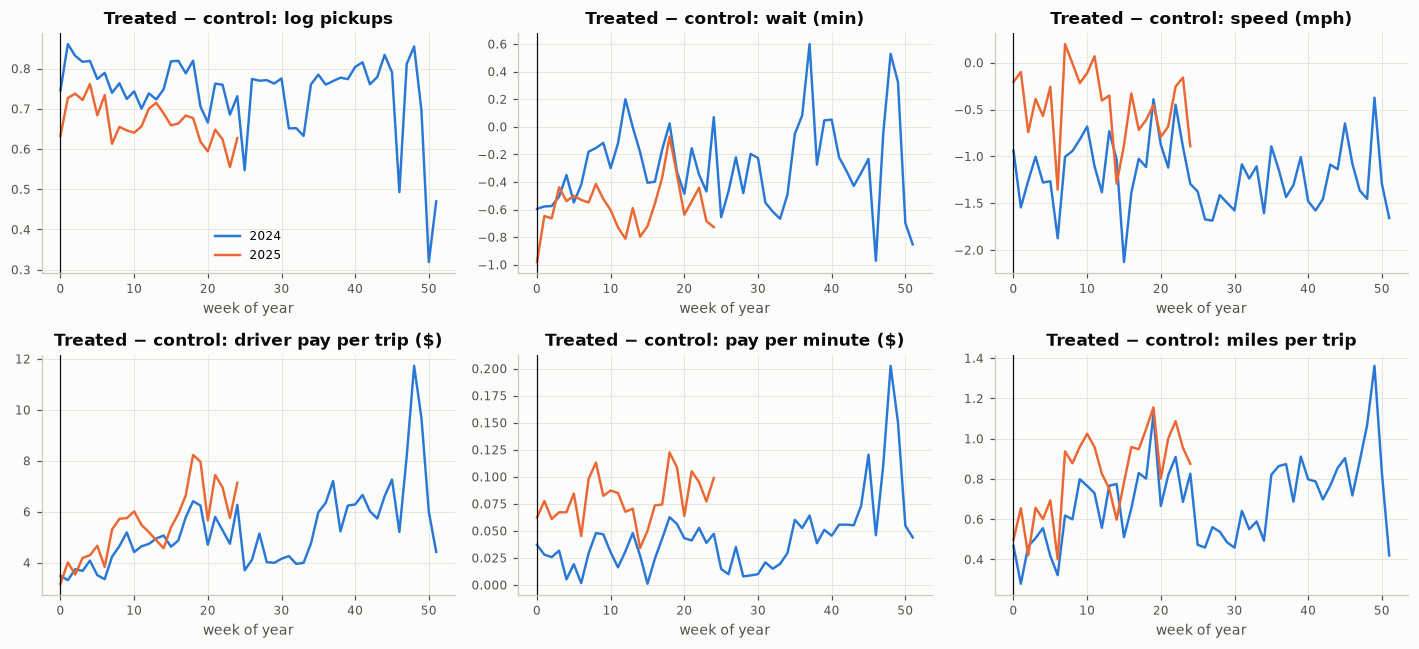

In [5]:
def wmean(d, col):
    return np.average(d[col], weights=d["w"])


gap = (main.groupby(["week", "group"]).apply(lambda d: pd.Series({c: wmean(d, c) for c in OUTCOMES}),
                                             include_groups=False)
       .unstack("group"))
gap = pd.DataFrame({c: gap[(c, "treated")] - gap[(c, "control")] for c in OUTCOMES})
gap["year"], gap["woy"] = gap.index.year, (gap.index - gap.index.year.map(lambda y: pd.Timestamp(y, 1, 1))).days // 7
fig, axes = plots.subplots(2, 3, figsize=(13, 6))
titles = {"log_trips": "log pickups", "wait_min": "wait (min)", "mph": "speed (mph)",
          "pay_per_trip": "driver pay per trip ($)", "pay_per_min": "pay per minute ($)", "miles": "miles per trip"}
for ax, c in zip(axes.ravel(), OUTCOMES):
    for i, yr in enumerate(sorted(gap["year"].unique())):
        g = gap[gap["year"] == yr]
        ax.plot(g["woy"], g[c], color=plots.SERIES[i], lw=1.6, label=str(yr))
    ax.axvline(0, color=plots.INK, lw=0.8)
    ax.set_title(f"Treated − control: {titles[c]}")
    ax.set_xlabel("week of year")
axes[0, 0].legend()
fig.tight_layout()
data.savefig(fig, "04_gap_by_year")

## Event study

Regression on the weekly panel: zone fixed effects, week fixed effects, and a treated × week
coefficient for every week (the reference is the average of the 2024 weeks with the same calendar
weeks as the post period, so 2024 Jan–Jun is the baseline). Coefficients for 2024 H2 test for
pre-existing divergence; 2025 coefficients are the effect path.

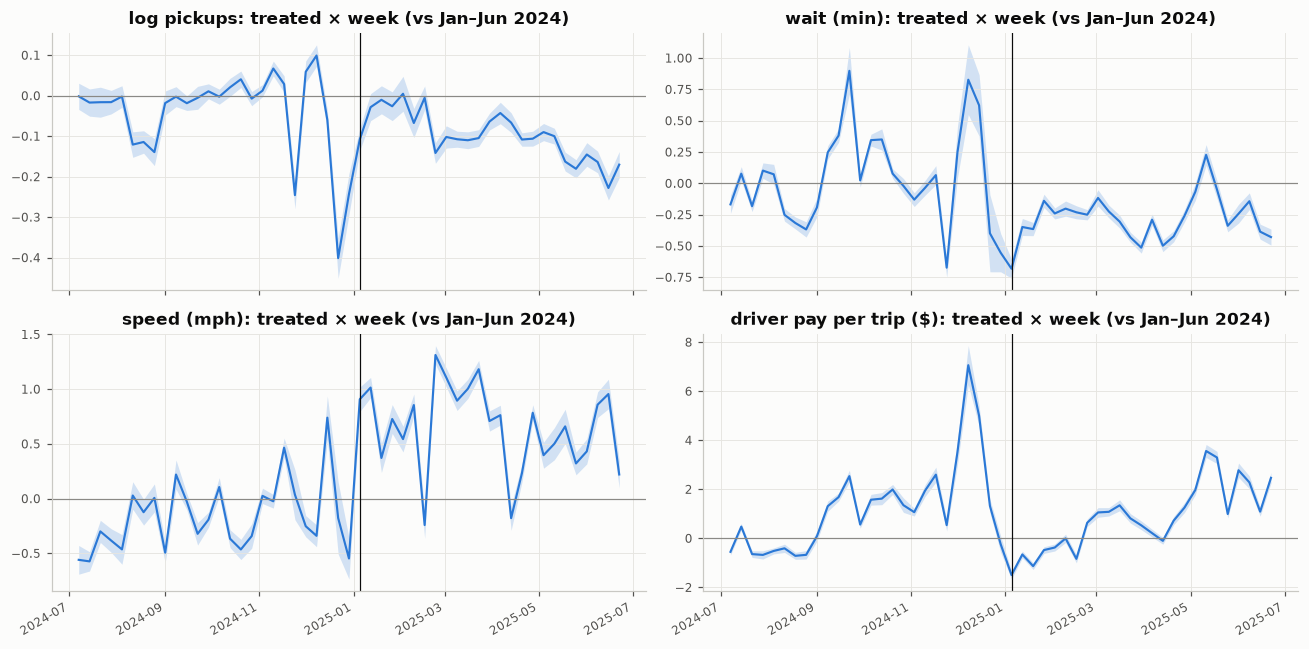

In [6]:
def event_study(df, outcome, weight=True):
    d = df.copy()
    base = (d["year"] == 2024) & (d["woy"] < 26)                  # same calendar weeks as the post period, a year earlier
    # control zones and treated base weeks form the reference; one dummy per other treated week
    d["evt"] = np.where(d["treated"] == 1, d["week"].dt.strftime("%Y-%m-%d"), "base")
    d.loc[(d["treated"] == 1) & base, "evt"] = "base"
    formula = f"{outcome} ~ C(zone) + C(week) + C(evt, Treatment('base'))"
    fit = smf.wls(formula, d, weights=d["w"] if weight else np.ones(len(d))).fit(
        cov_type="cluster", cov_kwds={"groups": d["zone"]})
    rows = []
    for name, b in fit.params.items():
        if name.startswith("C(evt"):
            wk = name.split("[T.")[1].rstrip("]")
            lo, hi = fit.conf_int().loc[name]
            rows.append({"week": pd.Timestamp(wk), "coef": b, "lo": lo, "hi": hi})
    return pd.DataFrame(rows).sort_values("week")


es = {c: event_study(main, c, weight=(c != "log_trips")) for c in ["log_trips", "wait_min", "mph", "pay_per_trip"]}
fig, axes = plots.subplots(2, 2, figsize=(12, 6), sharex=True)
for ax, (c, r) in zip(axes.ravel(), es.items()):
    ax.fill_between(r["week"], r["lo"], r["hi"], color=plots.SERIES[0], alpha=0.2, lw=0)
    ax.plot(r["week"], r["coef"], color=plots.SERIES[0], lw=1.4)
    ax.axhline(0, color=plots.GREY, lw=0.8)
    ax.axvline(FEE_START, color=plots.INK, lw=0.8)
    ax.set_title(f"{titles[c]}: treated × week (vs Jan–Jun 2024)")
fig.autofmt_xdate()
fig.tight_layout()
data.savefig(fig, "04_event_study")

## Main estimate: year-over-year difference-in-differences

Only Jan–Jun of each year, so every post week has its own pre week one year earlier:

`y[zone, week] = zone effect + week effect + δ · treated × 2025`

δ is the change in the treated–control gap from 2024 to 2025 in the same weeks of the year.
The six-month pre-period gap trend (2024 H2) is reported alongside: if the gap was already moving
in the half-year before the fee, the year-over-year comparison would attribute that drift to the fee.

In [7]:
def did(df, outcome, weight=True):
    d = df.copy()
    d["tp"] = d["treated"] * d["post"]
    fit = smf.wls(f"{outcome} ~ C(zone) + C(week) + tp", d, weights=d["w"] if weight else np.ones(len(d))).fit(
        cov_type="cluster", cov_kwds={"groups": d["zone"]})
    lo, hi = fit.conf_int().loc["tp"]
    return {"estimate": fit.params["tp"], "se": fit.bse["tp"], "lo": lo, "hi": hi, "p": fit.pvalues["tp"]}


h1 = main[main["woy"] < 26]
pre_level = main[(main["post"] == 0) & (main["year"] == 2024) & (main["woy"] < 26)]
rows = []
for c in OUTCOMES:
    r = did(h1, c, weight=(c != "log_trips"))
    base = (np.exp(pre_level[pre_level["treated"] == 1]["log_trips"]).mean() if c == "log_trips"
            else wmean(pre_level[pre_level["treated"] == 1], c))
    # drift: the treated-control gap trend over the 26 weeks before the fee (per 26 weeks)
    pre = main[(main["week"] < FEE_START) & (main["week"] >= FEE_START - pd.Timedelta(weeks=26))].copy()
    pre["t"] = (pre["week"] - pre["week"].min()).dt.days / 7 / 26
    pre["tt"] = pre["treated"] * pre["t"]
    drift = smf.wls(f"{c} ~ C(zone) + C(week) + tt", pre, weights=pre["w"] if c != "log_trips" else np.ones(len(pre))).fit(
        cov_type="cluster", cov_kwds={"groups": pre["zone"]})
    rows.append({"outcome": c, **r, "pct_effect": (np.exp(r["estimate"]) - 1) * 100 if c == "log_trips"
                 else 100 * r["estimate"] / base, "baseline_2024": base,
                 "pre_drift_26w": drift.params["tt"], "pre_drift_p": drift.pvalues["tt"]})
results = pd.DataFrame(rows).set_index("outcome")
results.round(4)

,estimate,se,lo,hi,p,pct_effect,baseline_2024,pre_drift_26w,pre_drift_p
outcome,,,,,,,,,
log_trips,-0.0976,0.0078,-0.1129,-0.0823,0.0,-9.3014,32417.7642,-0.0863,0.0011
wait_min,-0.2787,0.0179,-0.3138,-0.2437,0.0,-6.4098,4.3487,0.0999,0.3175
mph,0.6526,0.0281,0.5975,0.7078,0.0,4.6454,14.0490,0.3716,0.0000
pay_per_trip,0.8356,0.0653,0.7076,0.9635,0.0,3.8864,21.5002,4.0541,0.0000
pay_per_min,0.0462,0.0016,0.0431,0.0493,0.0,4.6092,1.0021,0.1084,0.0000
miles,0.1679,0.0116,0.1452,0.1906,0.0,3.3419,5.0241,0.4525,0.0000


## Placebo tests: is the design's noise bigger than its standard errors say?

Zone-clustered standard errors treat each zone's weeks as one cluster, but all Manhattan zones share
the same weekly shocks (a holiday season, a heat wave, a parade). Those common shocks are not in the
standard errors, so "significant" can be too easy. The check: pretend the fee started on each
alternate Sunday from April to October 2024 (no fee anywhere) and run the same difference-in-
differences on the 12 weeks either side. The spread of these placebo estimates is the design's real
noise. The real start date gets the same windowed estimate, and is ranked against them.

In [8]:
OUT4 = ["log_trips", "wait_min", "mph", "pay_per_trip"]


def windowed(d0):
    win = main[(main["week"] >= d0 - pd.Timedelta(weeks=12)) & (main["week"] < d0 + pd.Timedelta(weeks=12))].copy()
    win["post"] = (win["week"] >= d0).astype(int)
    return {c: did(win, c, weight=(c != "log_trips")) for c in OUT4}


placebo_dates = pd.date_range("2024-04-07", "2024-10-06", freq="14D")
prow = []
for d0 in placebo_dates:
    for c, r in windowed(d0).items():
        prow.append({"fake_start": d0.date(), "outcome": c, "estimate": r["estimate"], "p": r["p"]})
placebo_long = pd.DataFrame(prow)
placebo = placebo_long.pivot(index="fake_start", columns="outcome", values=["estimate", "p"])
real_win = windowed(FEE_START)
rank = pd.DataFrame({
    "real date estimate (±12 weeks)": {c: real_win[c]["estimate"] for c in OUT4},
    "placebo estimates: min": placebo_long.groupby("outcome")["estimate"].min(),
    "placebo estimates: max": placebo_long.groupby("outcome")["estimate"].max(),
    "placebos 'significant' at 5%": placebo_long.assign(sig=placebo_long["p"] < 0.05).groupby("outcome")["sig"].mean(),
    "year-over-year estimate": results.loc[OUT4, "estimate"],
})
rank["placebo p (share of |placebo| ≥ |real|)"] = [
    (1 + (placebo_long.loc[placebo_long["outcome"] == c, "estimate"].abs() >= abs(real_win[c]["estimate"])).sum())
    / (1 + len(placebo_dates)) for c in OUT4]
rank["robust"] = (rank["placebo p (share of |placebo| ≥ |real|)"] <= 0.1) & (
    np.sign(rank["real date estimate (±12 weeks)"]) == np.sign(rank["year-over-year estimate"]))
rank.round(4)

,real date estimate (±12 weeks),placebo estimates: min,placebo estimates: max,placebos 'significant' at 5%,year-over-year estimate,placebo p (share of |placebo| ≥ |real|),robust
log_trips,-0.0148,-0.0623,0.0627,0.7143,-0.0976,0.8000,False
mph,0.9104,-0.3206,0.1835,0.7143,0.6526,0.0667,True
pay_per_trip,-2.3178,-0.8600,2.3295,0.9286,0.8356,0.0667,False
wait_min,-0.3264,-0.2171,0.2444,0.9286,-0.2787,0.1333,False


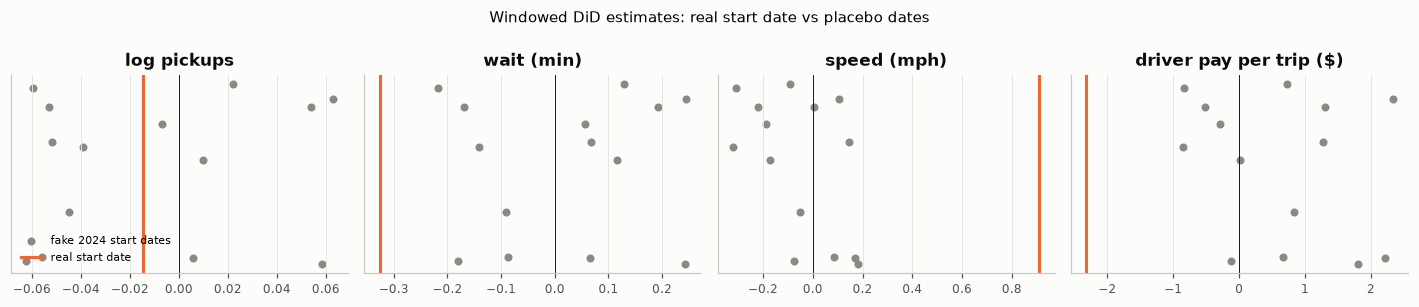

In [9]:
fig, axes = plots.subplots(1, 4, figsize=(13, 2.8))
for ax, c in zip(axes, OUT4):
    v = placebo_long.loc[placebo_long["outcome"] == c, "estimate"]
    ax.scatter(v, np.zeros(len(v)) + np.random.default_rng(0).uniform(-0.3, 0.3, len(v)), color=plots.GREY, s=18,
               label="fake 2024 start dates")
    ax.axvline(real_win[c]["estimate"], color=plots.SERIES[1], lw=2, label="real start date")
    ax.axvline(0, color=plots.INK, lw=0.6)
    ax.set_yticks([])
    ax.set_title(titles[c])
axes[0].legend(fontsize=7, loc="lower left")
fig.suptitle("Windowed DiD estimates: real start date vs placebo dates", fontsize=10)
fig.tight_layout()
data.savefig(fig, "04_placebo_ranks")

## Dose–response: partly exposed zones

If the fee is the cause, zones where a larger share of pickups pay it should move more. Each
partly exposed zone gets its own year-over-year change relative to the control zones.

In [10]:
dose_df = weekly[(weekly["woy"] < 26) & weekly["group"].isin(["control", "partly exposed", "treated"])].copy()
dose_df["exposure"] = dose_df["zone"].map(exposure["fee_share_after"]).where(dose_df["group"] != "control", 0.0)
dose_df["exp_post"] = dose_df["exposure"] * dose_df["post"]
dose = {}
for c in ["log_trips", "mph", "pay_per_trip"]:
    f = smf.wls(f"{c} ~ C(zone) + C(week) + exp_post", dose_df,
                weights=dose_df["w"] if c != "log_trips" else np.ones(len(dose_df))).fit(
        cov_type="cluster", cov_kwds={"groups": dose_df["zone"]})
    dose[c] = {"per_unit_exposure": f.params["exp_post"], "se": f.bse["exp_post"], "p": f.pvalues["exp_post"]}
pd.DataFrame(dose).T.round(4)

,per_unit_exposure,se,p
log_trips,-0.1007,0.0077,0.0
mph,0.6558,0.0274,0.0
pay_per_trip,0.8543,0.0644,0.0


In [11]:
record = {
    "fee_start": str(FEE_START.date()),
    "groups": exposure.groupby("group").size().to_dict(),
    "treated_examples": treated.sort_values("trips", ascending=False)["zone_name"].head(8).tolist(),
    "yoy_did": results.reset_index().round(6).to_dict(orient="records"),
    "placebo": placebo_long.astype({"fake_start": str}).round(6).to_dict(orient="records"),
    "placebo_rank": rank.reset_index().rename(columns={"index": "outcome"}).round(6).to_dict(orient="records"),
    "dose_response": dose,
    "event_study": {c: r.assign(week=r["week"].dt.strftime("%Y-%m-%d")).round(6).to_dict(orient="records")
                    for c, r in es.items()},
}
_ = write_metrics("04_congestion_fee", record, SOURCE)

## Verdict

In [12]:
R = results


def describe(c, unit, scale=1.0, pct=True):
    r = R.loc[c]
    return (f"{r['estimate'] * scale:+.2f}{unit} ({r['pct_effect']:+.1f}%; zone-clustered 95% CI "
            f"{r['lo'] * scale:+.2f} to {r['hi'] * scale:+.2f})")


robust = rank["robust"]
sig_share = float(placebo_long["p"].lt(0.05).mean())


def tag(c):
    return "robust to placebo dates" if robust[c] else "not distinguishable from placebo noise"


show_verdict(
    "Verdict: phase 4, the congestion fee",
    [
        f"**Treated and control groups come from the data**: {record['groups'].get('treated', 0)} zones where ≥80% of "
        f"pickups pay the fee after 5 January 2025 (all in Manhattan below 60th St), {record['groups'].get('control', 0)} "
        "control zones where <10% do; before the start date no trip carries the fee.",
        f"**Zone-clustered standard errors are too optimistic here**: {sig_share:.0%} of placebo estimates at fake 2024 "
        "dates come out 'significant' at 5%. Treated zones share weekly shocks that clustering by zone ignores, so each "
        "result is judged against the placebo distribution instead.",
        f"**Traffic got faster in the zone ({tag('mph')})**: {describe('mph', ' mph')} year over year; the "
        f"dose–response agrees ({dose['mph']['per_unit_exposure']:+.2f} mph from no exposure to full exposure).",
        f"**Pickups in the zone: direction clear, size uncertain.** Year over year, pickups fell "
        f"{-R.loc['log_trips', 'pct_effect']:.1f}% relative to control zones, but the gap was already drifting "
        f"({R.loc['log_trips', 'pre_drift_26w']:+.3f} log points in the 26 weeks before) and the ±12-week estimate around "
        f"the start date, which also spans the holidays, is only {(np.exp(real_win['log_trips']['estimate']) - 1) * 100:+.1f}% "
        f"({tag('log_trips')}). Two reasonable designs disagree on size, so report a range, not a number.",
        f"**Waits and driver pay per trip: no measurable effect.** Point estimates: wait "
        f"{R.loc['wait_min', 'estimate']:+.2f} min ({tag('wait_min')}), pay per trip {R.loc['pay_per_trip', 'estimate']:+.2f} "
        f"dollars ({tag('pay_per_trip')}). The honest answer for these is \"not measurable with this design\": a "
        "pricing team should not book a driver-pay effect from the fee.",
    ],
    "phase 5: how does a driver's acceptance respond to pay, and why can't we read that from the history?",
)

### Verdict: phase 4, the congestion fee

1. **Treated and control groups come from the data**: 39 zones where ≥80% of pickups pay the fee after 5 January 2025 (all in Manhattan below 60th St), 166 control zones where <10% do; before the start date no trip carries the fee.
2. **Zone-clustered standard errors are too optimistic here**: 82% of placebo estimates at fake 2024 dates come out 'significant' at 5%. Treated zones share weekly shocks that clustering by zone ignores, so each result is judged against the placebo distribution instead.
3. **Traffic got faster in the zone (robust to placebo dates)**: +0.65 mph (+4.6%; zone-clustered 95% CI +0.60 to +0.71) year over year; the dose–response agrees (+0.66 mph from no exposure to full exposure).
4. **Pickups in the zone: direction clear, size uncertain.** Year over year, pickups fell 9.3% relative to control zones, but the gap was already drifting (-0.086 log points in the 26 weeks before) and the ±12-week estimate around the start date, which also spans the holidays, is only -1.5% (not distinguishable from placebo noise). Two reasonable designs disagree on size, so report a range, not a number.
5. **Waits and driver pay per trip: no measurable effect.** Point estimates: wait -0.28 min (not distinguishable from placebo noise), pay per trip +0.84 dollars (not distinguishable from placebo noise). The honest answer for these is "not measurable with this design": a pricing team should not book a driver-pay effect from the fee.

**Next:** phase 5: how does a driver's acceptance respond to pay, and why can't we read that from the history?